### Markov Chain Monte Carlo to Simulate 2D Ising Model

Consider the Hamiltonian of Ising spins ($\sigma_i = \pm 1$)

$$\mathcal{H} = - J' \sum_{\langle i j \rangle} \sigma_i \sigma_j - H' \sum_i \sigma_i$$

so that $J' > 0$ corresponds to ferromagnetism. We will scale the energy and the Hamiltonian by $\beta \equiv 1/k_B T$ and work with the reduced Hamiltonian

$$\beta \mathcal{H} = - J \sum_{\langle i j \rangle} \sigma_i \sigma_j - H \sum_i \sigma_i$$

where now $J \equiv J'/k_B T$ and $H\equiv H'/k_B T$ are dimensionless, but of course depend on the temperature. At zero external magnetic field for a particular spin system, for instance, varying the temperature is the same as varying the coupling constant $J$.

$$ J_{crit} = \ln (1 + \sqrt{2})/2.$$
This is the scaled dimensionless coupling term. The critical coupling therefore is another way of writing the critical temperature $T_{crit}\equiv (J'/k_B)\frac{2}{\ln (1 + \sqrt{2})}\approx 2.269\times (J'/k_B)$, see Eq 5.75 in Gould & Tobochnik.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Lx, Ly = 10, 10  # Square lattice
Jcrit = np.log(1+np.sqrt(2.))/2
J = 2.0 * Jcrit
H = 0

In [3]:
sigma = np.random.choice([-1,1],[Lx,Ly])  # Random initial configuration

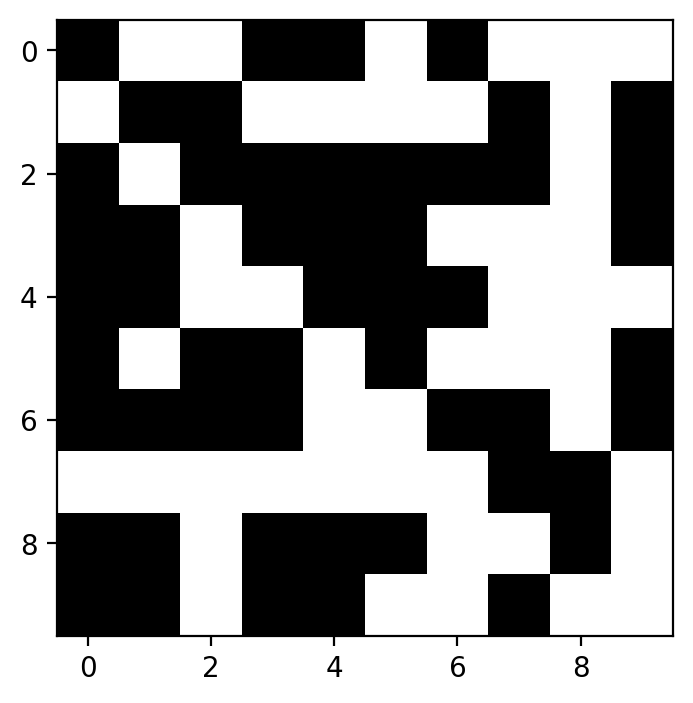

In [4]:
plt.figure(figsize=(4,4), dpi=200)
im = plt.imshow(sigma, cmap='gray', vmin=-1, vmax=1)

In [5]:
def energy(sigma):
    return  ( -J * np.sum(sigma*np.roll(sigma, 1, axis = 0)) 
            + -J * np.sum(sigma*np.roll(sigma, 1, axis = 1))
            + -H * np.sum(sigma))

In [6]:
# Version 1 - inefficient but easier to understand
# Go through the array laboriously and replace spins using the Monte Carlo algorithm
def mcflip(sigma):
    """Loop through sites and randomly flip with probability
    set by the relative Gibbs-Boltzmann weight."""
    
    e0 = energy(sigma)

    for i in range(Lx):
        for j in range(Ly):
            # propose flip
            sigma[i,j] *= -1         # Note: multiplying by -1 is flipping the spin
            
            e1 = energy(sigma)
            
            deltaE = e1 - e0
            p = np.exp(- deltaE)/(np.exp(- deltaE) + np.exp(deltaE))
            
            if np.random.rand() < p:
                # accept flip and new energy
                e0 = e1
            else:
                # reject flip
                sigma[i,j] *= -1
                
    return

In [7]:
# With periodic boundary conditions PBCm but not calling energy(sigma)
def mcflip(sigma):
    """Loop through sites and randomly flip with probability
    set by the relative Gibbs-Boltzmann weight."""
    
    # Heat-bath asks:
    # Given all neighbors fixed, what should this spin statistically be right now?
    
    # Metropolis: current spin matters because you test flipping current state
    # Heat-Bath: current spin irrelevant, only neighbor environment matters
    
    for i in range(Lx):
        for j in range(Ly):
            # calculate local field 
            localH = H
            localH += J*(sigma[(i+1)%Lx,j] +
                        sigma[(i-1)%Lx,j] +
                        sigma[i,(j+1)%Ly] +
                        sigma[i,(j-1)%Ly])
            
            
            # sample a spin configuration 
            m = np.tanh(localH)
            
            # p=prob(s=+1) 
            p = (m+1)/2
            
            # sigma[i,j] = 1 w prob p, -1 w prob 1-p
            sigma[i,j] = 2*(np.random.rand() < p) - 1
                
    return

In [8]:
def mcflip_sublat(sigma, a, b, bc='periodic', fixed_spin=1):
    """
    Update one checkerboard sublattice sigma[a::2, b::2]
    using vectorized heat-bath sampling.
    """

    # Select spins with row parity a and column parity b:
    # (0,0)=even/even, (1,0)=odd/even, etc
    
    if bc == 'periodic':
        # For every selected site, build arrays containing its
        # four nearest neighbors using periodic boundaries
        right = np.roll(sigma,  1, axis=0)[a::2, b::2]
        left  = np.roll(sigma, -1, axis=0)[a::2, b::2]
        up    = np.roll(sigma,  1, axis=1)[a::2, b::2]
        down  = np.roll(sigma, -1, axis=1)[a::2, b::2]
    
    elif bc == 'free' or bc == 'fixed':
        # For every selected site, build arrays containing its
        # four nearest neighbors using free or fixed-free boundaries
        
        # pad the lattice with free or fixed boundary
        padded = np.pad(sigma, 1, mode="constant", constant_values=0)
        
        right = padded[:-2, 1:-1][a::2, b::2]
        left  = padded[2:,  1:-1][a::2, b::2]
        up    = padded[1:-1, :-2][a::2, b::2]
        down  = padded[1:-1, 2: ][a::2, b::2]
        
    else:
        raise ValueError("bc must be 'periodic', 'free', or 'fixed'")

    # Local field h_ij = H + J * sum(nearest neighbors)
    localH = H + J * (right + left + up + down)

    # Probability spin = +1 from heat-bath rule
    p = (np.tanh(localH) + 1) / 2

    # Update all spins in this sublattice simultaneously
    sigma[a::2, b::2] = 2 * (np.random.rand(Lx//2, Ly//2) < p) - 1
    
    # boundary spins must stay constant
    if bc == "fixed":
        sigma[0, :] = fixed_spin
        sigma[-1, :] = fixed_spin
        sigma[:, 0] = fixed_spin
        sigma[:, -1] = fixed_spin
    
def mcflip(sigma, bc='periodic'):
    # One full sweep through the four checkerboard sublattices
    mcflip_sublat(sigma,0,0, bc)   # even row, even col
    mcflip_sublat(sigma,1,0, bc)   # odd row, even col
    mcflip_sublat(sigma,0,1, bc)   # even row, odd col
    mcflip_sublat(sigma,1,1, bc)   # odd row, odd col